# Experiment 7 — Mobile robot simulation in Webots: reactive swarm and lidar navigation
CSAI4014 AISR Laboratory · github.com/reshamrajs/webots-robotics-sim (README.md, GUIDE.md)

**Run this on the computer where Webots R2025a is installed.** It drives the simulator project
(`webots-robotics-sim`, next to this repository) headless and writes everything the report needs:

* Part A — e-puck swarm, 120 s: default and `cruise=0.9`, **3 repeats each** (runs are not bit-for-bit repeatable).
* Part B — Pioneer 3-DX with lidar, 180 s: default, `bubble=0.15`, `k_turn=0.5`.
* Exercise 1 (GUIDE §10) — speed vs safety: `cruise` = 0.2, 0.4, 0.6, 0.8, 1.0, 3 repeats each.
* Exercise 4 (GUIDE §10) — simulation time step: `basicTimeStep` = 8, 32 (default) and 64 ms, 3 repeats each.

CSV files go to `runs/`, figures to `figs/`, numbers to `results.json`. About 30 runs; expect 10–15 minutes.
The screenshot for Figure 7.1 must be taken by hand (open `worlds/swarm_arena.wbt` in the Webots window).

In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.12.1', 'numpy': '2.3.2', 'matplotlib': '3.8.4', 'os': 'Windows 11', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'scipy': '1.16.1'}


## 0. Settings

In [2]:
from pathlib import Path
SIM_ROOT = Path("../../webots-robotics-sim").resolve()   # the simulator project folder
WEBOTS_HOME = None        # e.g. r"C:\Program Files\Webots" if Webots is not found automatically
REPEATS = 3
SWARM_S, PIONEER_S = 120, 180
assert (SIM_ROOT / "worlds" / "swarm_arena.wbt").is_file(), f"simulator project not found at {SIM_ROOT}"
RUNS = Path("runs"); RUNS.mkdir(exist_ok=True)
print("simulator project:", SIM_ROOT)

simulator project: C:\Users\huwai\Desktop\Sem 7\Robotics_Lab\webots-robotics-sim


In [3]:
import re, shutil, subprocess, time, math
import pandas as pd

def find_webots():
    home = WEBOTS_HOME or os.environ.get("WEBOTS_HOME")
    cands = []
    if home:
        cands += [os.path.join(home, "msys64", "mingw64", "bin", "webots.exe"),
                  os.path.join(home, "Contents", "MacOS", "webots"), os.path.join(home, "webots")]
    if platform.system() == "Windows":
        for base in (os.environ.get("ProgramFiles", r"C:\Program Files"),
                     os.path.join(os.environ.get("LOCALAPPDATA", ""), "Programs")):
            cands.append(os.path.join(base, "Webots", "msys64", "mingw64", "bin", "webots.exe"))
    elif platform.system() == "Darwin":
        cands.append("/Applications/Webots.app/Contents/MacOS/webots")
    else:
        cands += ["/usr/local/bin/webots", "/usr/bin/webots", "/snap/bin/webots"]
    for c in cands:
        if c and os.path.isfile(c):
            return c
    return shutil.which("webots")

WEBOTS = find_webots()
assert WEBOTS, "Webots not found: set WEBOTS_HOME in the settings cell"
print("Webots:", WEBOTS)
RESULTS["env"]["webots"] = "R2025a"

WORLDS = {"swarm": ("swarm_arena.wbt", "epuck_braitenberg"),
          "pioneer": ("pioneer_lidar.wbt", "pioneer_lidar_nav")}
GRID = {"swarm": (0.8, 0.1), "pioneer": (4.0, 0.5)}      # (arena half-width m, coverage cell m)

def run(world, seconds, label, params=None, timestep=None):
    """Write a temporary copy of the world with the parameters, run Webots headless, return the CSV path."""
    params = params or {}
    out = (RUNS / f"{label}.csv").resolve()
    wfile, ctrl = WORLDS[world]
    src = (SIM_ROOT / "worlds" / wfile).read_text(encoding="utf-8")
    args = " ".join(f'"--{k}={v}"' for k, v in params.items())
    src = src.replace(f'controller "{ctrl}"', f'controller "{ctrl}" controllerArgs [ {args} ]')
    log_args = f'"--seconds={seconds}" "--out={out.as_posix()}" "--quit=1"'
    src = re.sub(r'controller "trajectory_logger"(\s*controllerArgs \[[^\]]*\])?',
                 lambda m: f'controller "trajectory_logger" controllerArgs [ {log_args} ]', src)
    if timestep is not None:                    # Exercise 4: change WorldInfo basicTimeStep
        if "basicTimeStep" in src:
            src = re.sub(r"basicTimeStep\s+\d+", f"basicTimeStep {timestep}", src)
        else:
            src = src.replace("WorldInfo {", f"WorldInfo {{\n  basicTimeStep {timestep}", 1)
    tmp = SIM_ROOT / "worlds" / f"_experiment_{world}.wbt"
    tmp.write_text(src, encoding="utf-8")
    out.unlink(missing_ok=True)
    t0 = time.time()
    try:
        subprocess.run([WEBOTS, "--mode=fast", "--no-rendering", "--batch", "--minimize",
                        "--stdout", "--stderr", str(tmp)], capture_output=True, text=True,
                       timeout=max(600, seconds * 5))
    finally:
        tmp.unlink(missing_ok=True)
    assert out.exists() and out.stat().st_size > 100, f"{label}: no trajectory written"
    print(f"  {label}: done in {time.time() - t0:.0f} s")
    return out

def metrics(csv_path, world):
    """Same definitions as analysis/metrics.py: path, mean speed, stuck % (< 1 cm/s), coverage %."""
    half, cell = GRID[world]
    n = int(round(2 * half / cell))
    df = pd.read_csv(csv_path)
    per, visited = [], set()
    for name, g in df.groupby("robot"):
        d = np.hypot(np.diff(g["x"]), np.diff(g["y"]))
        dt = np.maximum(np.diff(g["t"]), 1e-9)
        dur = g["t"].iloc[-1] - g["t"].iloc[0]
        per.append({"robot": name, "path": d.sum(), "speed": d.sum() / dur,
                    "stuck": 100 * np.mean(d / dt < 0.01)})
        ix = np.minimum(n - 1, ((g["x"] + half) / cell).astype(int))
        iy = np.minimum(n - 1, ((g["y"] + half) / cell).astype(int))
        visited |= set(zip(ix, iy))
    per = pd.DataFrame(per)
    return {"path": per["path"].mean(), "speed": per["speed"].mean(),
            "stuck_mean": per["stuck"].mean(), "stuck_worst": per["stuck"].max(),
            "coverage": 100 * len(visited) / n**2, "per_robot": per.to_dict("records")}

Webots: C:\Users\huwai\AppData\Local\Programs\Webots\msys64\mingw64\bin\webots.exe


## 1. Part A — e-puck swarm, 3 repeats per setting

In [4]:
partA = []
for setting, params in (("default", {}), ("cruise=0.9", {"cruise": 0.9})):
    for rep in range(1, REPEATS + 1):
        label = f"swarm_{setting.replace('=', '-')}_r{rep}"
        m = metrics(run("swarm", SWARM_S, label, params), "swarm")
        partA.append({"setting": setting, "run": rep, **{k: v for k, v in m.items() if k != "per_robot"}})
A = pd.DataFrame(partA)
display(A.round(3))
summary_A = A.groupby("setting")[["path", "speed", "stuck_mean", "stuck_worst", "coverage"]].agg(["mean", "std"])
display(summary_A.round(3))
RESULTS["partA"] = partA

  swarm_default_r1: done in 25 s
  swarm_default_r2: done in 13 s
  swarm_default_r3: done in 13 s
  swarm_cruise-0.9_r1: done in 13 s
  swarm_cruise-0.9_r2: done in 13 s
  swarm_cruise-0.9_r3: done in 13 s


,setting,run,path,speed,stuck_mean,stuck_worst,coverage
0,default,1,6.153,0.051,7.112,29.947,80.469
1,default,2,6.153,0.051,7.112,29.947,80.469
2,default,3,6.153,0.051,7.112,29.947,80.469
3,cruise=0.9,1,10.657,0.089,3.636,4.813,85.938
4,cruise=0.9,2,10.657,0.089,3.636,4.813,85.938
5,cruise=0.9,3,10.657,0.089,3.636,4.813,85.938


path       speed      stuck_mean      stuck_worst      coverage  \
              mean  std   mean  std       mean  std        mean  std     mean   
setting                                                                         
cruise=0.9  10.657  0.0  0.089  0.0      3.636  0.0       4.813  0.0   85.938   
default      6.153  0.0  0.051  0.0      7.112  0.0      29.947  0.0   80.469   

                 
            std  
setting          
cruise=0.9  0.0  
default     0.0

## 2. Part B — Pioneer 3-DX with lidar

In [5]:
partB = []
for setting, params in (("default", {}), ("bubble=0.15", {"bubble": 0.15}), ("k_turn=0.5", {"k_turn": 0.5})):
    label = f"pioneer_{setting.replace('=', '-')}"
    m = metrics(run("pioneer", PIONEER_S, label, params), "pioneer")
    partB.append({"setting": setting, **{k: v for k, v in m.items() if k != "per_robot"}})
B = pd.DataFrame(partB); display(B.round(3))
RESULTS["partB"] = partB

  pioneer_default: done in 13 s
  pioneer_bubble-0.15: done in 10 s
  pioneer_k_turn-0.5: done in 9 s


,setting,path,speed,stuck_mean,stuck_worst,coverage
0,default,83.591,0.466,0.000,0.000,22.656
1,bubble=0.15,13.393,0.075,78.075,78.075,12.109
2,k_turn=0.5,74.322,0.414,0.000,0.000,28.516


## 3. Exercise 1 — speed against safety (cruise sweep)

  ex1_cruise-0.2_r1: done in 14 s
  ex1_cruise-0.2_r2: done in 13 s
  ex1_cruise-0.2_r3: done in 12 s
  ex1_cruise-0.4_r1: done in 13 s
  ex1_cruise-0.4_r2: done in 13 s
  ex1_cruise-0.4_r3: done in 12 s
  ex1_cruise-0.6_r1: done in 12 s
  ex1_cruise-0.6_r2: done in 12 s
  ex1_cruise-0.6_r3: done in 15 s
  ex1_cruise-0.8_r1: done in 13 s
  ex1_cruise-0.8_r2: done in 12 s
  ex1_cruise-0.8_r3: done in 12 s
  ex1_cruise-1.0_r1: done in 12 s
  ex1_cruise-1.0_r2: done in 12 s
  ex1_cruise-1.0_r3: done in 12 s


run      coverage      stuck_worst        path     
       mean  std     mean  std        mean  std   mean  std
cruise                                                     
0.2     2.0  1.0    56.25  0.0        0.27  0.0   2.73  0.0
0.4     2.0  1.0    76.95  0.0        1.60  0.0   5.23  0.0
0.6     2.0  1.0    80.86  0.0        3.21  0.0   7.65  0.0
0.8     2.0  1.0    83.59  0.0        4.01  0.0   9.56  0.0
1.0     2.0  1.0    85.94  0.0        6.15  0.0  11.50  0.0

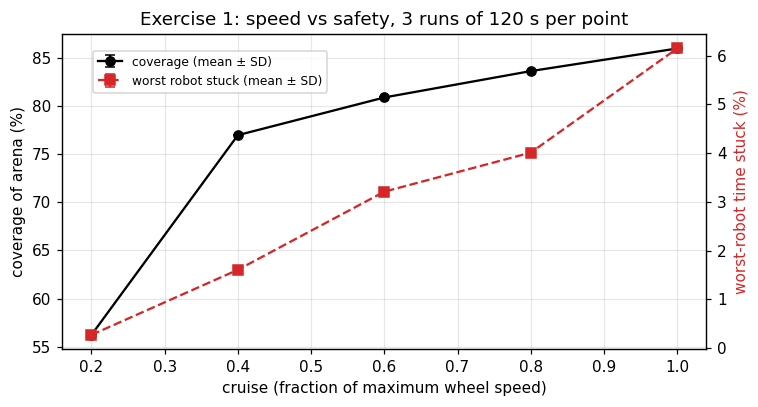

In [6]:
ex1 = []
for cruise in (0.2, 0.4, 0.6, 0.8, 1.0):
    for rep in range(1, REPEATS + 1):
        m = metrics(run("swarm", SWARM_S, f"ex1_cruise-{cruise}_r{rep}", {"cruise": cruise}), "swarm")
        ex1.append({"cruise": cruise, "run": rep, "coverage": m["coverage"], "stuck_worst": m["stuck_worst"],
                    "path": m["path"]})
E1 = pd.DataFrame(ex1)
S1 = E1.groupby("cruise").agg(["mean", "std"]); display(S1.round(2))
RESULTS["ex1"] = ex1

fig, ax1 = plt.subplots(figsize=(7, 3.8))
ax1.errorbar(S1.index, S1["coverage"]["mean"], yerr=S1["coverage"]["std"], fmt="o-", color="k",
             capsize=3, label="coverage (mean ± SD)")
ax1.set(xlabel="cruise (fraction of maximum wheel speed)", ylabel="coverage of arena (%)")
ax2 = ax1.twinx()
ax2.errorbar(S1.index, S1["stuck_worst"]["mean"], yerr=S1["stuck_worst"]["std"], fmt="s--",
             color="tab:red", capsize=3, label="worst robot stuck (mean ± SD)")
ax2.set_ylabel("worst-robot time stuck (%)", color="tab:red"); ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88), fontsize=8)
ax1.set_title(f"Exercise 1: speed vs safety, {REPEATS} runs of {SWARM_S} s per point")
fig.tight_layout(); save(fig, "fig7_4_ex1_speed_vs_safety.png"); plt.show()

## 4. Exercise 4 — simulation time step

  ex4_timestep-8_r1: done in 36 s
  ex4_timestep-8_r2: done in 36 s
  ex4_timestep-8_r3: done in 37 s
  ex4_timestep-32_r1: done in 12 s
  ex4_timestep-32_r2: done in 13 s
  ex4_timestep-32_r3: done in 12 s
  ex4_timestep-64_r1: done in 8 s
  ex4_timestep-64_r2: done in 8 s
  ex4_timestep-64_r3: done in 8 s


run      coverage      stuck_mean      stuck_worst       path  \
            mean  std     mean  std       mean  std        mean  std  mean   
timestep_ms                                                                  
8            2.0  1.0    82.81  0.0       0.15  0.0        0.20  0.0  6.82   
32           2.0  1.0    80.47  0.0       7.11  0.0       29.95  0.0  6.15   
64           2.0  1.0    63.28  0.0      10.97  0.0       15.59  0.0  5.10   

                  
             std  
timestep_ms       
8            0.0  
32           0.0  
64           0.0

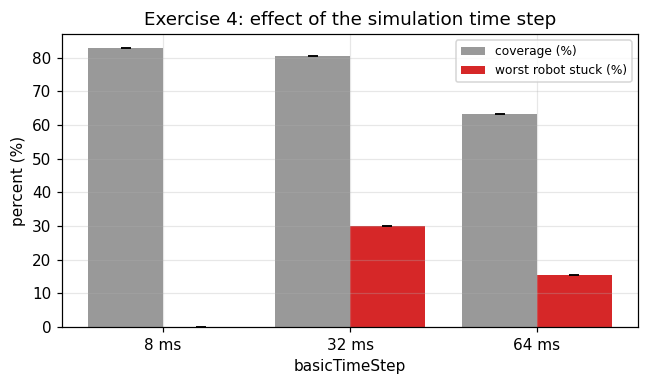

In [7]:
ex4 = []
for ts in (8, 32, 64):
    for rep in range(1, REPEATS + 1):
        m = metrics(run("swarm", SWARM_S, f"ex4_timestep-{ts}_r{rep}", timestep=ts), "swarm")
        ex4.append({"timestep_ms": ts, "run": rep, "coverage": m["coverage"], "stuck_mean": m["stuck_mean"],
                    "stuck_worst": m["stuck_worst"], "path": m["path"]})
E4 = pd.DataFrame(ex4)
S4 = E4.groupby("timestep_ms").agg(["mean", "std"]); display(S4.round(2))
RESULTS["ex4"] = ex4

fig, ax = plt.subplots(figsize=(6, 3.6))
x = np.arange(len(S4))
ax.bar(x - 0.2, S4["coverage"]["mean"], 0.4, yerr=S4["coverage"]["std"], capsize=3, color="0.6", label="coverage (%)")
ax.bar(x + 0.2, S4["stuck_worst"]["mean"], 0.4, yerr=S4["stuck_worst"]["std"], capsize=3, color="tab:red",
       label="worst robot stuck (%)")
ax.set_xticks(x); ax.set_xticklabels([f"{t} ms" for t in S4.index])
ax.set(xlabel="basicTimeStep", ylabel="percent (%)", title="Exercise 4: effect of the simulation time step")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "fig7_5_ex4_timestep.png"); plt.show()

## 5. Trajectory figures (Figures 7.2 and 7.3)

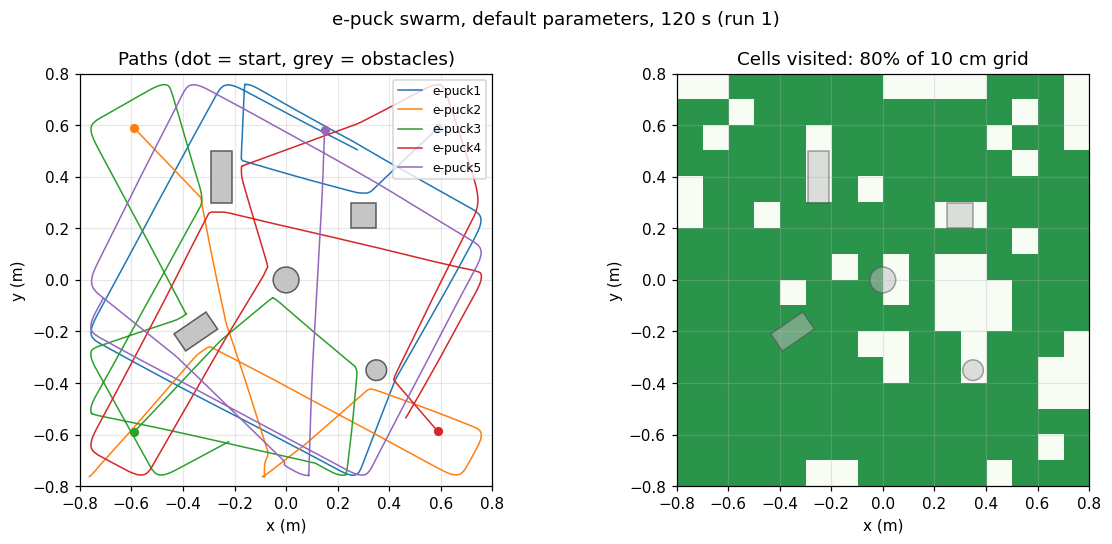

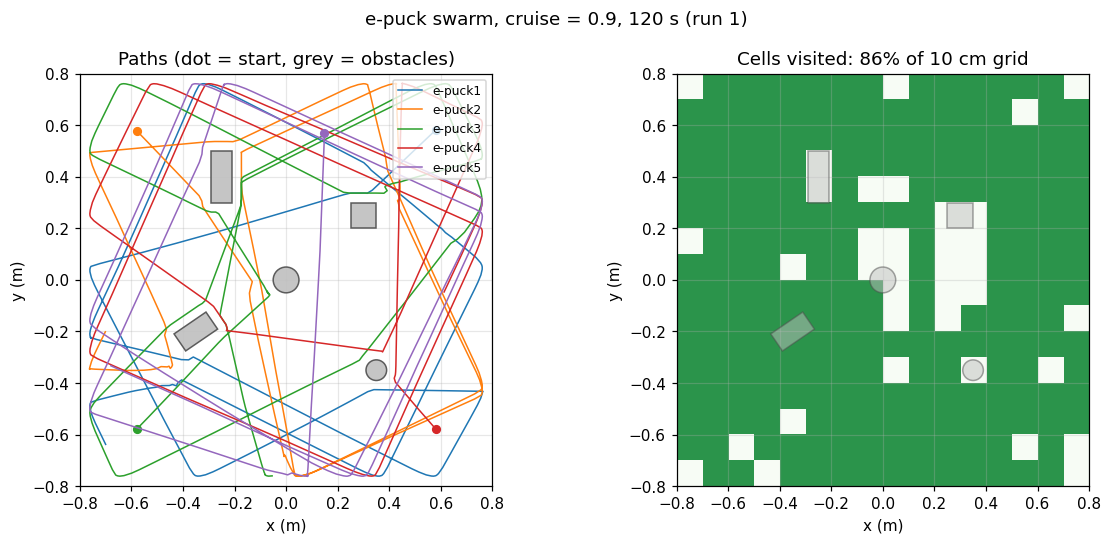

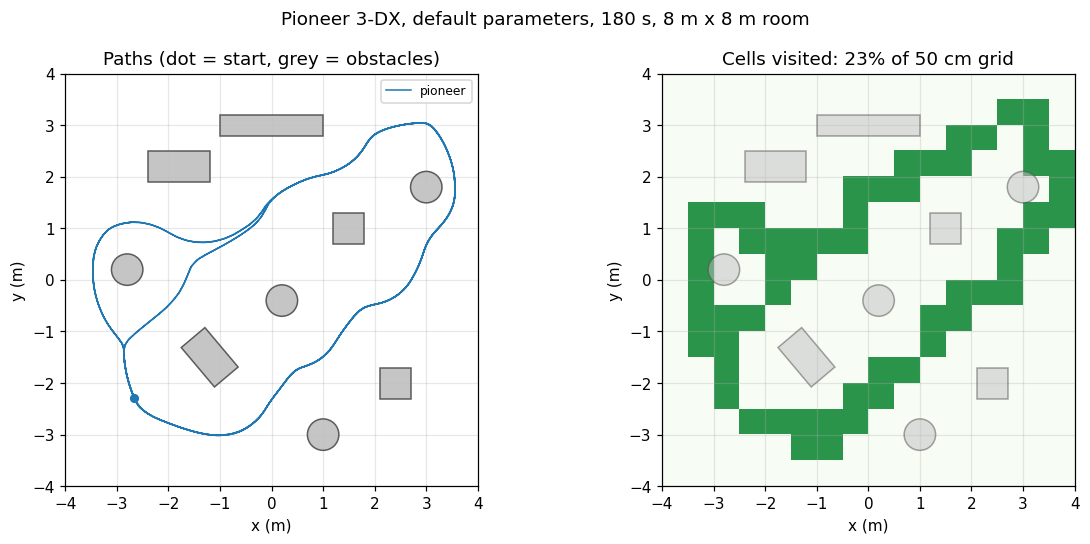

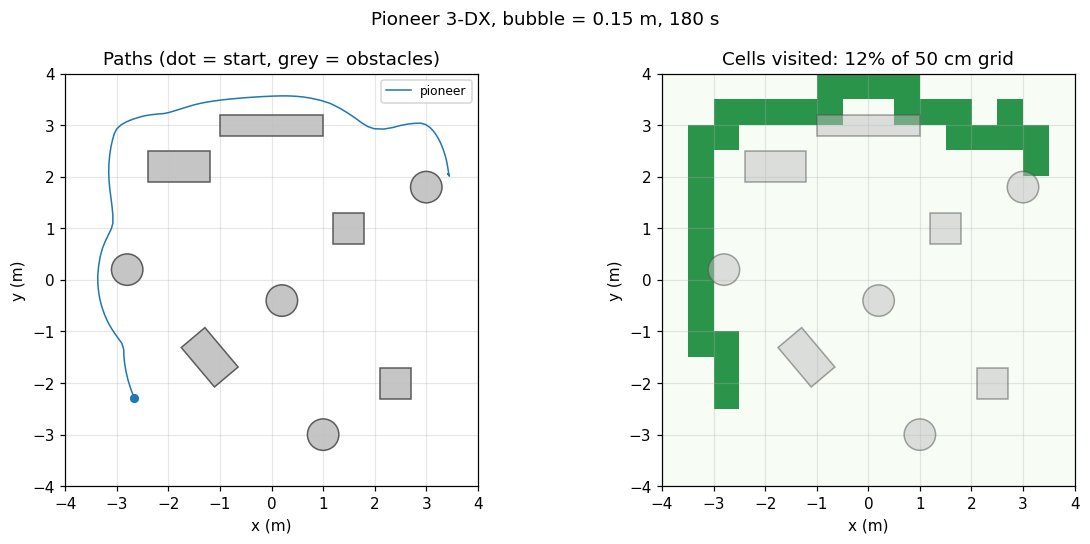

In [8]:
from matplotlib.patches import Circle, Polygon

def obstacles(world):
    txt = (SIM_ROOT / "worlds" / WORLDS[world][0]).read_text(encoding="utf-8")
    num = r"(-?[\d.]+(?:e-?\d+)?)"
    out = []
    for kind, body in re.findall(r"(WoodenBox|OilBarrel)\s*\{([^}]*)\}", txt):
        tr = re.search(rf"translation {num} {num}", body)
        x0, y0 = (float(tr[1]), float(tr[2])) if tr else (0.0, 0.0)
        if kind == "OilBarrel":
            r = re.search(rf"radius {num}", body); out.append(Circle((x0, y0), float(r[1]) if r else 0.305))
        else:
            s = re.search(rf"size {num} {num}", body); sx, sy = (float(s[1]), float(s[2])) if s else (0.6, 0.6)
            a = re.search(rf"rotation 0 0 1 {num}", body); a = float(a[1]) if a else 0.0
            c, sn = math.cos(a), math.sin(a)
            out.append(Polygon([(x0 + c*px - sn*py, y0 + sn*px + c*py)
                                for px, py in ((-sx/2, -sy/2), (sx/2, -sy/2), (sx/2, sy/2), (-sx/2, sy/2))]))
    return out

def plot_run(csv_path, world, title, fname):
    half, cell = GRID[world]
    df = pd.read_csv(csv_path)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
    for ax in (ax1, ax2):
        for p in obstacles(world):
            p.set(facecolor="0.75", edgecolor="0.3", alpha=0.9 if ax is ax1 else 0.5, zorder=3); ax.add_patch(p)
    for name, g in df.groupby("robot"):
        line, = ax1.plot(g["x"], g["y"], lw=1, label=name)
        ax1.plot(g["x"].iloc[0], g["y"].iloc[0], "o", ms=5, color=line.get_color())
    ax1.set(xlim=(-half, half), ylim=(-half, half), aspect="equal", xlabel="x (m)", ylabel="y (m)",
            title="Paths (dot = start, grey = obstacles)")
    ax1.legend(fontsize=8, loc="upper right")
    bins = int(round(2 * half / cell))
    Hh, _, _ = np.histogram2d(df["x"], df["y"], bins=bins, range=[[-half, half]] * 2)
    ax2.imshow(Hh.T > 0, origin="lower", extent=(-half, half, -half, half), cmap="Greens", vmin=0, vmax=1.4)
    ax2.set(title=f"Cells visited: {(Hh > 0).mean():.0%} of {cell*100:.0f} cm grid", aspect="equal",
            xlabel="x (m)", ylabel="y (m)")
    fig.suptitle(title); fig.tight_layout(); save(fig, fname); plt.show()

plot_run(RUNS / "swarm_default_r1.csv", "swarm", f"e-puck swarm, default parameters, {SWARM_S} s (run 1)",
         "fig7_2_swarm_trajectories.png")
plot_run(RUNS / "swarm_cruise-0.9_r1.csv", "swarm", f"e-puck swarm, cruise = 0.9, {SWARM_S} s (run 1)",
         "fig7_6_swarm_cruise09.png")
plot_run(RUNS / "pioneer_default.csv", "pioneer", f"Pioneer 3-DX, default parameters, {PIONEER_S} s, 8 m x 8 m room",
         "fig7_3_pioneer_trajectory.png")
plot_run(RUNS / "pioneer_bubble-0.15.csv", "pioneer", f"Pioneer 3-DX, bubble = 0.15 m, {PIONEER_S} s",
         "fig7_7_pioneer_bubble015.png")

In [9]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 6 figures in figs/
